# Feature engineering

La stratégie `multivariate_4_history` de `imputation_testing.ipynb` est conservée.
Son historique exclut la visite actuelle et sert uniquement aux imputeurs.

Le preprocessing est ajusté une seule fois par fold sur le train, puis appliqué à sa validation.
Les cinq folds préparés sont réutilisés pour tous les essais. Rejouer leur préparation seulement
si les données, le preprocessing ou les splits changent.
Les nouvelles features sont calculées depuis les valeurs brutes ; leur imputation et le modèle
restent dans une pipeline ajustée sur le train de chaque fold.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor

DATA_DIR = Path("data") if Path("data").is_dir() else Path("../data")
X = pd.read_csv(DATA_DIR / "X_train_6ZIKlTY.csv")
Y = pd.read_csv(DATA_DIR / "y_train_lXj6X5y.csv")
assert X["Index"].equals(Y["Index"])
y = Y["target"]


Tools used to create a pipeline made to create new features used by multivariate imputers later

In [2]:
# Score/dose summaries exclude the current visit.
diagnosis_history = [
    "ledd_first_observed", "time_to_first_observed_ledd", "time_since_first_visit",
]
history_features = diagnosis_history + [
    f"{col}_{stat}_patient" for col in ["on", "off", "ledd"] for stat in ["median", "slope"]
] + ["disease_duration"]

def median_other_visits(s):
    values = np.tile(s.to_numpy(), (len(s), 1))
    np.fill_diagonal(values, np.nan)
    available = ~np.isnan(values).all(axis=1)
    medians = np.full(len(s), np.nan)
    medians[available] = np.nanmedian(values[available], axis=1)
    return medians

def add_patient_history(df):
    visits = df.sort_values(["patient_id", "age"])
    first_age = visits.groupby("patient_id")["age"].min()
    first_dose = visits.dropna(subset=["ledd"]).drop_duplicates("patient_id").set_index("patient_id")
    out = df.copy()
    out["ledd_first_observed"] = out["patient_id"].map(first_dose["ledd"])
    out["time_to_first_observed_ledd"] = out["patient_id"].map(first_dose["age"]) - out["patient_id"].map(first_age)
    out["time_since_first_visit"] = out["age"] - out["patient_id"].map(first_age)
    out["disease_duration"] = out["age"] - out["age_at_diagnosis"]
    t = out["time_since_first_visit"]
    for col in ["on", "off", "ledd"]:
        v = df[col]
        out[f"{col}_median_patient"] = df.groupby("patient_id")[col].transform(median_other_visits)
        # Subtract this visit's contributions from the patient's regression sums.
        sums = pd.DataFrame({"n": v.notna().astype(int), "t": t.where(v.notna(), 0),
                             "v": v.fillna(0), "tt": (t*t).where(v.notna(), 0), "tv": (t*v).fillna(0)})
        others = sums.groupby(df["patient_id"]).transform("sum") - sums
        denominator = others["n"] * others["tt"] - others["t"]**2
        out[f"{col}_slope_patient"] = (
            (others["n"] * others["tv"] - others["t"] * others["v"]) / denominator
        ).where((others["n"] >= 3) & (denominator > 1e-12))
    return out

Create the pipeline that do all processing steps including helper features creation, imputer training and cleaning of the dataset to be ready for training model on

In [3]:
encoder = ColumnTransformer(
    [("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
      ["cohort", "gene"])],
    remainder="passthrough", verbose_feature_names_out=False,
).set_output(transform="pandas")

preprocessor = Pipeline([
    ("encoding", encoder),
    ("remove_ids", FunctionTransformer(
        lambda df: df.drop(columns=["Index", "patient_id"])
    )),
])

predictors_history = {
    "age_at_diagnosis": ["age"] + diagnosis_history,
    "on": ["off", "age_at_diagnosis", "on_median_patient",
           "off_median_patient", "ledd_median_patient", "disease_duration",
           "time_since_first_visit", "on_slope_patient"],
    "off": ["on", "age_at_diagnosis", "time_since_intake_on", "on_median_patient",
            "off_median_patient", "ledd_median_patient",
            "time_since_first_visit", "off_slope_patient"],
    "ledd": ["age", "age_at_diagnosis", "on", "cohort_A",
             "off_median_patient", "ledd_median_patient", "disease_duration",
             "time_since_first_visit", "ledd_slope_patient"],
}

class PredictiveImputer(TransformerMixin, BaseEstimator):
    def __init__(self, predictors):
        self.predictors = predictors

    def fit(self, X, y=None):
        self.medians_, self.models_ = X.median(), {}
        self.indicator_ = MissingIndicator(error_on_new=False).set_output(
            transform="pandas"
        ).fit(X.drop(columns=history_features))
        for col, features in self.predictors.items():
            observed = X[col].notna()
            self.models_[col] = HistGradientBoostingRegressor(
                max_iter=50, max_leaf_nodes=15, random_state=42
            ).fit(X.loc[observed, features], X.loc[observed, col])
        return self

    def transform(self, X):
        filled = X.copy()
        for col, features in self.predictors.items():
            missing = X[col].isna()
            if missing.any():
                values = self.models_[col].predict(X.loc[missing, features])
                if col == "age_at_diagnosis":  # Diagnosis cannot follow this visit.
                    values = values.clip(max=X.loc[missing, "age"].to_numpy())
                filled.loc[missing, col] = values
        if "disease_duration" in filled:
            filled["disease_duration"] = filled["age"] - filled["age_at_diagnosis"]
        # History supports imputation only; indicators describe the original missingness.
        values = filled.fillna(self.medians_).drop(columns=history_features)
        indicators = self.indicator_.transform(X.drop(columns=history_features)).astype(float)
        return pd.concat([values, indicators], axis=1)

imputation_pipeline = make_pipeline(preprocessor, PredictiveImputer(predictors_history))
preprocessing = make_pipeline(FunctionTransformer(add_patient_history), imputation_pipeline)


Préparer et garder en mémoire les cinq folds imputés ; à exécuter une seule fois avant les essais.


In [4]:
cv = GroupShuffleSplit(n_splits=5, test_size=0.2, random_state=42)
clean_folds = []
for train_idx, val_idx in cv.split(X, y, groups=X["patient_id"]):
    fitted = clone(preprocessing)
    clean_folds.append({
        "X_train": fitted.fit_transform(X.iloc[train_idx]),
        "X_val": fitted.transform(X.iloc[val_idx]),
        "y_train": y.iloc[train_idx], "y_val": y.iloc[val_idx],
    })


Comparer les modèles avec une pipeline pour les nouveaux traitements, en réutilisant les folds préparés.


In [5]:
models = {
    "LR": make_pipeline(StandardScaler(), LinearRegression()),
    # "SVM": make_pipeline(StandardScaler(), SVR()),
    "RandomForest": RandomForestRegressor(random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(random_state=42),
    "HistGB": HistGradientBoostingRegressor(random_state=42),
}

# Seules les nouvelles colonnes peuvent encore avoir des NaN.
feature_imputer = SimpleImputer(
    strategy="median", add_indicator=True, keep_empty_features=True
).set_output(transform="pandas")
feature_experiments = {"baseline": pd.DataFrame(index=X.index)}

def evaluate_features(experiments, reference="baseline"):
    scores = []
    for experiment, features in experiments.items():
        for fold in clean_folds:
            # Une fonction apprend ses features sur le train du fold ; cache partagé entre modèles.
            if callable(features):
                cache = fold.setdefault("feature_cache", {})
                if experiment not in cache:
                    cache[experiment] = features(
                        X.loc[fold["X_train"].index], X.loc[fold["X_val"].index]
                    )
                train_features, val_features = cache[experiment]
            else:
                train_features = val_features = features
            train = fold["X_train"].join(train_features)
            validation = fold["X_val"].join(val_features)
            for name, model in models.items():
                pipeline = make_pipeline(clone(feature_imputer), clone(model))
                pipeline.fit(train, fold["y_train"])
                mse = mean_squared_error(fold["y_val"], pipeline.predict(validation))
                scores.append([experiment, name, mse])
    results = pd.DataFrame(scores, columns=["experiment", "model", "MSE"])
    results = results.groupby(["experiment", "model"], sort=False).agg(
        MSE=("MSE", "mean"), std=("MSE", lambda s: s.std(ddof=0))
    ).reset_index()
    baseline = results.loc[results["experiment"].eq(reference)].set_index("model")["MSE"]
    results["delta_MSE"] = results["MSE"] - results["model"].map(baseline)
    return results.sort_values(["model", "MSE"]).reset_index(drop=True)


Define new features and lunch the tests of performance


In [6]:
# Features recalculées depuis X brut, indépendamment des colonnes des imputeurs.
def build_visit_features(data):
    patients = data.groupby("patient_id")
    ages = patients["age"]
    features = pd.DataFrame(index=data.index)

    # Temps écoulé et visites strictement antérieures/ultérieures (hors âges identiques).
    features["time_since_first_visit"] = data["age"] - ages.transform("min")
    features["n_past_visits"] = (ages.rank(method="min") - 1).astype(int)
    features["n_future_visits"] = (ages.transform("size") - ages.rank(method="max")).astype(int)
    for col in ["on", "off", "ledd"]:
        # Médiane de toutes les mesures observées, visite actuelle comprise.
        values = data[col]
        features[f"{col}_median_patient"] = patients[col].transform("median")

        # Pente annuelle de la droite ajustée : au moins deux âges observés distincts.
        age = data["age"].where(values.notna())
        dt = age - age.groupby(data["patient_id"]).transform("mean")
        dv = values - patients[col].transform("mean")
        covariance = (dt * dv).groupby(data["patient_id"]).transform("sum")
        variance = (dt**2).groupby(data["patient_id"]).transform("sum")
        features[f"{col}_slope_patient"] = (covariance / variance).where(variance > 1e-12)
    gap = data["off"] - data["on"]  # NaN si un des deux scores manque.
    features["off_on_median_patient"] = gap.groupby(data["patient_id"]).transform("median")
    features["disease_duration"] = data["age"] - data["age_at_diagnosis"]
    # Interactions dose/délai, calculées uniquement depuis les valeurs brutes.
    for score in ["on", "off"]:
        t = data[f"time_since_intake_{score}"]
        features[f"ledd_x_time_{score}"] = data["ledd"] * t
        # Ratios désactivés : pas de gain convaincant sur visit_history ; conservés pour réessai.
        # features[f"ledd_time_ratio_{score}"] = data["ledd"] / (1 + t)
    return features



In [7]:
# Quatre groupes ajoutés séparément aux features actuelles, puis tous ensemble.
def build_feature_groups(data):
    patients = data.groupby("patient_id")
    history = build_visit_features(data)
    groups = {name: pd.DataFrame(index=data.index)
              for name in ["trend", "neighbors", "counts", "dispersion"]}
    visits = data.sort_values(["patient_id", "age"])
    for col in ["on", "off"]:
        # Niveau de la droite du patient à l'âge actuel (visite actuelle comprise).
        mean_age = data["age"].where(data[col].notna()).groupby(data["patient_id"]).transform("mean")
        groups["trend"][f"{col}_trend_at_visit"] = patients[col].transform("mean") + (
            history[f"{col}_slope_patient"] * (data["age"] - mean_age)
        )
        groups["dispersion"][f"{col}_std_patient"] = patients[col].transform("std")

        # Mesures observées voisines, en sautant les NaN et en excluant la visite actuelle.
        observed = visits[[col, "age"]].where(visits[col].notna(), axis=0)
        for label, shift, fill in [("previous", 1, "ffill"), ("next", -1, "bfill")]:
            neighbor = getattr(observed.groupby(visits["patient_id"]), fill)()
            neighbor = neighbor.groupby(visits["patient_id"]).shift(shift)
            groups["neighbors"][f"{col}_{label}"] = neighbor[col]
            groups["neighbors"][f"{col}_{label}_gap"] = (visits["age"] - neighbor["age"]).abs()
    for col in ["on", "off", "ledd"]:
        groups["counts"][f"{col}_n_observed"] = patients[col].transform("count")
    groups["all_groups"] = pd.concat(groups.values(), axis=1)
    return {name: history.join(extra) for name, extra in groups.items()}



In [8]:
feature_experiments["visit_history"] = build_visit_features(X)
feature_experiments.update(build_feature_groups(X))

# Comparer chaque groupe et leur combinaison, sur les mêmes cinq folds imputés.
results = evaluate_features(feature_experiments)
reference = results.loc[results["experiment"].eq("visit_history")].set_index("model")["MSE"]
results["gain_vs_current_pct"] = 100 * (1 - results["MSE"] / results["model"].map(reference))
results


,experiment,model,MSE,std,delta_MSE,gain_vs_current_pct
0,all_groups,HistGB,14.779276,0.300886,-30.507117,31.512427
1,neighbors,HistGB,17.136359,0.445168,-28.150034,20.589639
2,trend,HistGB,18.145034,0.237680,-27.141359,15.915411
3,dispersion,HistGB,19.290495,0.336662,-25.995898,10.607315
4,counts,HistGB,20.527295,0.486196,-24.759098,4.875950
5,visit_history,HistGB,21.579501,0.499600,-23.706892,0.000000
6,baseline,HistGB,45.286393,0.908592,0.000000,-109.858392
7,all_groups,LR,21.180271,0.371892,-30.777915,20.815868
8,neighbors,LR,23.109037,0.447336,-28.849149,13.605021
9,dispersion,LR,25.069177,0.485640,-26.889010,6.276884


### Résidus de validation — HistGB avec `all_groups`

Avant ajout de l’effet médicamenteux et optimisation des hyperparamètres.
Réutilise les cinq `clean_folds` et réentraîne uniquement HistGB avec l’imputation des features ajoutées.
Chaque point représente une visite ; les prédictions répétées en validation sont moyennées.
Résidu = cible réelle − prédiction (positif : sous-estimation).


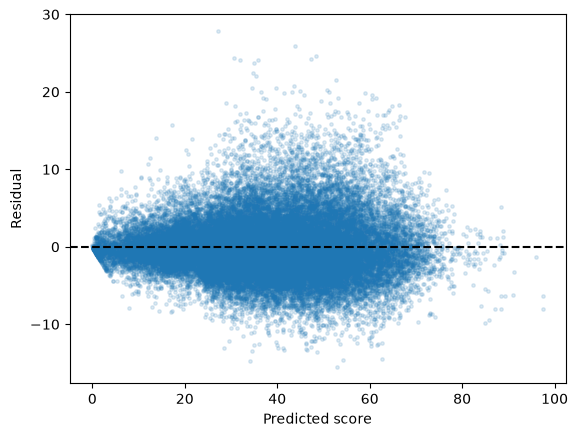

In [9]:
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits

with threadpool_limits(limits=3):
    validation_predictions = pd.concat([
        pd.Series(
            make_pipeline(clone(feature_imputer), clone(models["HistGB"]))
            .fit(fold["X_train"].join(feature_experiments["all_groups"]), fold["y_train"])
            .predict(fold["X_val"].join(feature_experiments["all_groups"])),
            index=fold["y_val"].index)
        for fold in clean_folds
    ]).groupby(level=0).mean()
residuals = y.loc[validation_predictions.index] - validation_predictions
ax = pd.DataFrame({"Predicted score": validation_predictions, "Residual": residuals}).plot.scatter(
    x="Predicted score", y="Residual", s=6, alpha=0.15)
ax.axhline(0, color="black", linestyle="--")
plt.show()


### Réglage rapide de HistGB sur `all_groups`

Recherche bayésienne [Optuna TPE](https://optuna.readthedocs.io/en/stable/tutorial/10_key_features/003_efficient_optimization_algorithms.html),
40 essais reproductibles, avec arrêt des configurations peu prometteuses après au moins deux folds.
On réutilise les cinq splits patients et les données prétraitées ; l'imputation des features ajoutées
est ajustée une seule fois sur le train de chaque fold. Le premier essai reprend les paramètres actuels.
Le gain mesuré sur les folds utilisés pour la recherche reste exploratoire, sans évaluation indépendante.
Dépendance : `optuna` (`%pip install optuna` si nécessaire).

**Résultat des 40 essais :** MSE 14,7793 → 13,1108 (−11,29 %), RMSE 3,8444 → 3,6209 (−5,81 %).
Le meilleur essai atteint la borne de 800 itérations ; cette recherche donne un premier gain, pas un optimum garanti.


In [10]:
import optuna
from threadpoolctl import threadpool_limits

N_TRIALS = 40
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Préparer all_groups une seule fois, sans réajuster les imputeurs à chaque essai.
tuning_folds = []
for fold in clean_folds:
    imputer = clone(feature_imputer)
    train = imputer.fit_transform(fold["X_train"].join(feature_experiments["all_groups"]))
    validation = imputer.transform(fold["X_val"].join(feature_experiments["all_groups"]))
    tuning_folds.append((train, validation, fold["y_train"], fold["y_val"]))


def histgb_objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "max_iter": trial.suggest_int("max_iter", 100, 800, step=100),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 7, 63, log=True),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 120, log=True),
        "l2_regularization": trial.suggest_float("l2_regularization", 0, 30),
        "max_features": trial.suggest_float("max_features", 0.6, 1.0),
    }
    scores = []
    for step, (train, validation, yt, yv) in enumerate(tuning_folds):
        fitted = clone(models["HistGB"]).set_params(**params).fit(train, yt)
        scores.append(mean_squared_error(yv, fitted.predict(validation)))
        trial.report(float(np.mean(scores)), step)
        if step < len(tuning_folds) - 1 and trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("fold_mse", scores)
    return float(np.mean(scores))


histgb_study = optuna.create_study(
    direction="minimize", sampler=optuna.samplers.TPESampler(seed=42),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=1),
)
parameter_names = ["learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf", "l2_regularization", "max_features"]
histgb_study.enqueue_trial({name: models["HistGB"].get_params()[name] for name in parameter_names})
with threadpool_limits(limits=3):
    histgb_study.optimize(histgb_objective, n_trials=N_TRIALS)

baseline_scores = histgb_study.trials[0].user_attrs["fold_mse"]
best_scores = histgb_study.best_trial.user_attrs["fold_mse"]
tuning_summary = pd.DataFrame([
    {"model": name, "MSE": np.mean(scores), "std": np.std(scores)}
    for name, scores in [("HistGB_default", baseline_scores), ("HistGB_tuned", best_scores)]
]).set_index("model")
tuning_summary["RMSE"] = np.sqrt(tuning_summary["MSE"])
tuning_summary["gain_MSE_pct"] = 100 * (1 - tuning_summary["MSE"] / np.mean(baseline_scores))
best_histgb = clone(models["HistGB"]).set_params(**histgb_study.best_params)
print("Meilleurs paramètres :", histgb_study.best_params)
tuning_summary


Meilleurs paramètres : {'learning_rate': 0.042592090635273853, 'max_iter': 800, 'max_leaf_nodes': 62, 'min_samples_leaf': 25, 'l2_regularization': 1.8115270802885095, 'max_features': 0.6078232265551354}


,MSE,std,RMSE,gain_MSE_pct
model,,,,
HistGB_default,14.779276,0.300886,3.844382,0.00000
HistGB_tuned,13.110847,0.321916,3.620890,11.28898


### Soumission rapide du meilleur modèle

HistGB optimisé avec **all_groups** : MSE de validation **13,110847**.
Les paramètres du meilleur essai sont repris directement : un seul entraînement sur tout le train.
Pour une exécution rapide depuis un noyau vide, exécuter les cinq cellules de définitions
marquées `submission_setup` (imports/données, historique, preprocessing, `build_visit_features`,
`build_feature_groups`), puis la cellule ci-dessous. Les folds, comparaisons et Optuna peuvent être sautés.


In [ ]:
from time import perf_counter
from threadpoolctl import threadpool_limits

# Meilleur essai sauvegardé : HistGB + all_groups, MSE = 13.110847.
# Aucun fold ni recherche Optuna à relancer.
best_params = {
    "learning_rate": 0.042592090635273853, "max_iter": 800,
    "max_leaf_nodes": 62, "min_samples_leaf": 25,
    "l2_regularization": 1.8115270802885095, "max_features": 0.6078232265551354,
}
started = perf_counter()
X_test = pd.read_csv(DATA_DIR / "X_test_oiZ2ukx.csv")[X.columns]
selected = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True),
    HistGradientBoostingRegressor(random_state=42, **best_params),
)
with threadpool_limits(limits=3):
    full_preprocessor = clone(preprocessing)
    X_full = full_preprocessor.fit_transform(X).join(build_feature_groups(X)["all_groups"])
    X_test_final = full_preprocessor.transform(X_test).join(build_feature_groups(X_test)["all_groups"])
    selected.fit(X_full, y)
    submission = pd.DataFrame({"Index": X_test["Index"], "target": selected.predict(X_test_final)})

assert submission["Index"].equals(X_test["Index"]) and np.isfinite(submission["target"]).all()
submission_path = DATA_DIR / "submission_4__10_23_2026_histgb_tuned.csv"
submission.to_csv(submission_path, index=False)
print(f"{submission_path} — {len(submission):,} lignes, {perf_counter() - started:.1f} s")
submission.head()
